# Architecture localization — results and error analysis

Analyze the completed 30-checkpoint frozen-readout experiment and five random-visual controls. Differences use **paired seeds**, not individual questions as independent replicates. All datasets used here are development splits and have been examined repeatedly.

In [1]:
from pathlib import Path
import sys, math
PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0,str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from IPython.display import display

SCHEDULES = ("mixed", "prereq_mixed_pair_focus")
SEEDS = (42, 43, 44, 45, 46)
STEPS = (5400, 7200, 9000)
READOUTS = ("pretrained", "scalar", "spatial", "tokens")
OUT_DIR = PROJECT_ROOT / "outputs/medium_world/experiments/architecture_localization"
DATA_DIR = OUT_DIR / "frozen_heads"
ANALYSIS_DIR = OUT_DIR / "analysis"
ANALYSIS_DIR.mkdir(parents=True,exist_ok=True)

id_frames=[]
edit_frames=[]
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            folder=DATA_DIR/f"{schedule}_seed{seed}_step{step}"
            for name,destination in (("id_metrics",id_frames),("edit_metrics",edit_frames)):
                frame=pd.read_csv(folder/(name+".csv"))
                frame["schedule"],frame["seed"],frame["step"]=schedule,seed,step
                destination.append(frame)
id_metrics = pd.concat(id_frames, ignore_index=True)
edit_metrics = pd.concat(edit_frames, ignore_index=True)
print("Finished frozen-checkpoint conditions:",len(SCHEDULES)*len(SEEDS)*len(STEPS))

Finished frozen-checkpoint conditions: 30


## 1. Original scene-level questions

Inspect Color and Shape accuracy, Conjunction's difficult **Color-present / Shape-absent** negatives, and count-controlled Binding balanced accuracy. A better average accuracy with no improvement on difficult negatives would not establish that the intended reasoning was repaired.

In [2]:
main_metrics=("id_color","id_shape","id_conjunction","id_conjunction_missing_shape",
              "id_pair","id_pair_count_controlled")
final=id_metrics[(id_metrics.step==9000) & id_metrics.metric.isin(main_metrics)]
display(final.pivot_table(index=["schedule","metric"],columns="readout",
                          values=["accuracy","tpr","tnr","balanced_accuracy"],aggfunc="mean").round(3))

accuracy         \
readout                                              pretrained scalar   
schedule                metric                                           
mixed                   id_color                          0.992  0.994   
                        id_conjunction                    0.798  0.803   
                        id_conjunction_missing_shape      0.242  0.315   
                        id_pair                           0.620  0.662   
                        id_pair_count_controlled          0.574  0.673   
                        id_shape                          0.678  0.677   
prereq_mixed_pair_focus id_color                          0.994  0.995   
                        id_conjunction                    0.807  0.813   
                        id_conjunction_missing_shape      0.258  0.315   
                        id_pair                           0.630  0.638   
                        id_pair_count_controlled          0.598  0.624   
                        id_shape                          0.669  0.676   

                                                                     \
readout                                              spatial tokens   
schedule                metric                                        
mixed                   id_color                       0.991  0.977   
                        id_conjunction                 0.791  0.779   
                        id_conjunction_missing_shape   0.392  0.335   
                        id_pair                        0.738  0.634   
                        id_pair_count_controlled       0.728  0.629   
                        id_shape                       0.683  0.676   
prereq_mixed_pair_focus id_color                       0.992  0.979   
                        id_conjunction                 0.805  0.773   
                        id_conjunction_missing_shape   0.465  0.319   
                        id_pair                        0.716  0.680   
                        id_pair_count_controlled       0.695  0.662   
                        id_shape                       0.663  0.649   

                                                     balanced_accuracy         \
readout                                                     pretrained scalar   
schedule                metric                                                  
mixed                   id_color                                 0.992  0.994   
                        id_conjunction                           0.798  0.803   
                        id_conjunction_missing_shape               NaN    NaN   
                        id_pair                                  0.620  0.662   
                        id_pair_count_controlled                 0.625  0.669   
                        id_shape                                 0.678  0.677   
prereq_mixed_pair_focus id_color                                 0.994  0.995   
                        id_conjunction                           0.807  0.813   
                        id_conjunction_missing_shape               NaN    NaN   
                        id_pair                                  0.630  0.638   
                        id_pair_count_controlled                 0.639  0.638   
                        id_shape                                 0.669  0.676   

                                                                     \
readout                                              spatial tokens   
schedule                metric                                        
mixed                   id_color                       0.991  0.977   
                        id_conjunction                 0.791  0.779   
                        id_conjunction_missing_shape     NaN    NaN   
                        id_pair                        0.738  0.634   
                        id_pair_count_controlled       0.716  0.615   
                        id_shape                       0.683  0.676   
prereq_mixed_pair_focus

## 2. Controlled interventions

The strict Binding swap changes which attributes belong together while preserving the same counts and geometry. Shape insertion tests correct responses to altered geometry. Color-only edits test Shape invariance on both Shape-present and Shape-absent questions. Keep both-correct and correct-direction metrics separate.

In [3]:
intervention_metrics = ("strict_swap_all","strict_swap_id_safe",
                      "grid_shape_insert_shape_id_safe","shape_recolor_absent_id_safe",
                      "shape_recolor_present_id_safe","shape_recolor_all_id_safe")
final = edit_metrics[(edit_metrics.step==9000) & edit_metrics.metric.isin(intervention_metrics)]
display(final.pivot_table(index=["schedule","metric"],columns="readout",
                          values=["n_pairs","both_correct","correct_direction","invariant_prediction"],aggfunc="mean").round(3))

both_correct         \
readout                                                   pretrained scalar   
schedule                metric                                                
mixed                   grid_shape_insert_shape_id_safe        0.177  0.172   
                        shape_recolor_absent_id_safe           0.563  0.572   
                        shape_recolor_all_id_safe              0.535  0.530   
                        shape_recolor_present_id_safe          0.524  0.513   
                        strict_swap_all                        0.283  0.350   
                        strict_swap_id_safe                    0.277  0.345   
prereq_mixed_pair_focus grid_shape_insert_shape_id_safe        0.156  0.188   
                        shape_recolor_absent_id_safe           0.517  0.528   
                        shape_recolor_all_id_safe              0.530  0.530   
                        shape_recolor_present_id_safe          0.536  0.530   
                        strict_swap_all                        0.327  0.343   
                        strict_swap_id_safe                    0.319  0.339   

                                                                        \
readout                                                 spatial tokens   
schedule                metric                                           
mixed                   grid_shape_insert_shape_id_safe   0.219  0.205   
                        shape_recolor_absent_id_safe      0.596  0.547   
                        shape_recolor_all_id_safe         0.534  0.535   
                        shape_recolor_present_id_safe     0.509  0.530   
                        strict_swap_all                   0.486  0.319   
                        strict_swap_id_safe               0.448  0.326   
prereq_mixed_pair_focus grid_shape_insert_shape_id_safe   0.182  0.147   
                        shape_recolor_absent_id_safe      0.540  0.533   
                        shape_recolor_all_id_safe         0.527  0.502   
                        shape_recolor_present_id_safe     0.521  0.490   
                        strict_swap_all                   0.473  0.349   
                        strict_swap_id_safe               0.465  0.361   

                                                        correct_direction  \
readout                                                        pretrained   
schedule                metric                                              
mixed                   grid_shape_insert_shape_id_safe             0.735   
                        shape_recolor_absent_id_safe                  NaN   
                        shape_recolor_all_id_safe                     NaN   
                        shape_recolor_present_id_safe                 NaN   
                        strict_swap_all                             0.690   
                        strict_swap_id_safe                         0.684   
prereq_mixed_pair_focus grid_shape_insert_shape_id_safe             0.736   
                        shape_recolor_absent_id_safe                  NaN   
                        shape_recolor_all_id_safe                     NaN   
                        shape_recolor_present_id_safe                 NaN   
                        strict_swap_all                             0.706   
                        strict_swap_id_safe                         0.710   

                                                                               \
readout                                                 scalar spatial tokens   
schedule                metric                                                  
mixed                   grid_shape_insert_shape_id_safe  0.735   0.725  0.736   
                        shape_recolor_absent_id_safe       NaN     NaN    NaN   
                        shape_recolor_all_id_safe          NaN     NaN    NaN   
                        shape_recolor_present_id_safe      NaN     NaN    NaN   
                        strict_swap_

## 3. Paired readout contrasts

Compare **Spatial − Scalar**, then **Tokens − Spatial**, and finally **Tokens − Scalar** on the same seed, curriculum, checkpoint and controlled questions. Two-sided 95% paired *t* intervals are descriptive (five seeds; many comparisons). Positive results must agree across the intended behavior metrics, not only overall accuracy.

In [4]:
def paired_interval(values):
    d=np.asarray(values,dtype=float)
    n=len(d)
    mean=float(d.mean())
    sd=float(d.std(ddof=1))
    half=float(student_t.ppf(.975,n-1)*sd/math.sqrt(n))
    return dict(n_seeds=n,mean_pp=mean,sd_pp=sd,ci95_low=mean-half,
                ci95_high=mean+half,positive_seeds=int((d>0).sum()))

OUTCOMES=(
    ("id_shape","accuracy","id"),
    ("id_conjunction_missing_shape","accuracy","id"),
    ("id_pair_count_controlled","balanced_accuracy","id"),
    ("strict_swap_id_safe","both_correct","edit"),
    ("strict_swap_id_safe","correct_direction","edit"),
    ("grid_shape_insert_shape_id_safe","both_correct","edit"),
    ("shape_recolor_absent_id_safe","both_correct","edit"),
    ("shape_recolor_present_id_safe","both_correct","edit"),
)
CONTRASTS=(("spatial","scalar"),("tokens","spatial"),("tokens","scalar"))
paired_rows=[]
for schedule in SCHEDULES:
    for step in STEPS:
        for metric,column,source in OUTCOMES:
            df=id_metrics if source=="id" else edit_metrics
            subset=df[(df.schedule==schedule) & (df.step==step) & (df.metric==metric)]
            wide=subset.pivot(index="seed",columns="readout",values=column).loc[list(SEEDS)]
            for new,old in CONTRASTS:
                difference=(wide[new]-wide[old])*100
                paired_rows.append(dict(schedule=schedule, step=step, metric=metric,
                                        outcome=column, contrast=new+" - "+old,
                                        **paired_interval(difference)))
paired = pd.DataFrame(paired_rows)
display(paired[paired.step==9000].round(2))

,schedule,step,metric,outcome,contrast,n_seeds,mean_pp,sd_pp,ci95_low,ci95_high,positive_seeds
48,mixed,9000,id_shape,accuracy,spatial - scalar,5,0.62,1.80,-1.61,2.86,3
49,mixed,9000,id_shape,accuracy,tokens - spatial,5,-0.70,2.94,-4.36,2.95,2
50,mixed,9000,id_shape,accuracy,tokens - scalar,5,-0.08,2.38,-3.04,2.88,3
51,mixed,9000,id_conjunction_missing_shape,accuracy,spatial - scalar,5,7.69,6.52,-0.41,15.79,4
52,mixed,9000,id_conjunction_missing_shape,accuracy,tokens - spatial,5,-5.77,14.58,-23.88,12.34,2
53,mixed,9000,id_conjunction_missing_shape,accuracy,tokens - scalar,5,1.92,12.39,-13.46,17.31,2
54,mixed,9000,id_pair_count_controlled,balanced_accuracy,spatial - scalar,5,4.64,7.74,-4.97,14.26,4
55,mixed,9000,id_pair_count_controlled,balanced_accuracy,tokens - spatial,5,-10.09,8.50,-20.65,0.46,0
56,mixed,9000,id_pair_count_controlled,balanced_accuracy,tokens - scalar,5,-5.45,6.19,-13.13,2.23,1
57,mixed,9000,strict_swap_id_safe,both_correct,spatial - scalar,5,10.32,9.45,-1.41,22.05,4


## 4. How readout behavior differs across frozen checkpoints

Each new readout is fitted separately at 5,400, 7,200, and 9,000 updates of the **pretrained ViT**. The plots compare what is accessible at each frozen checkpoint; they do not show uninterrupted training of the same new readout over those steps.

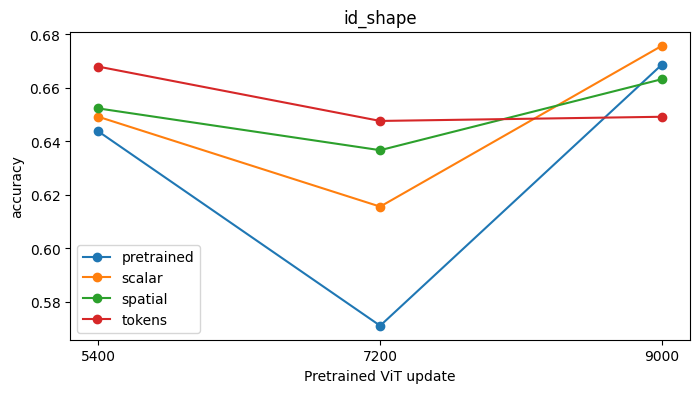

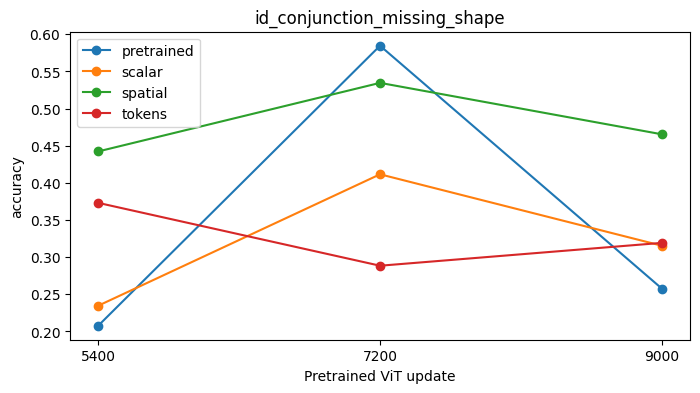

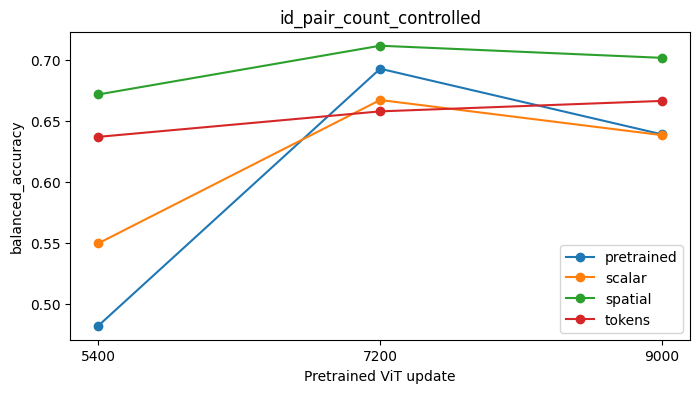

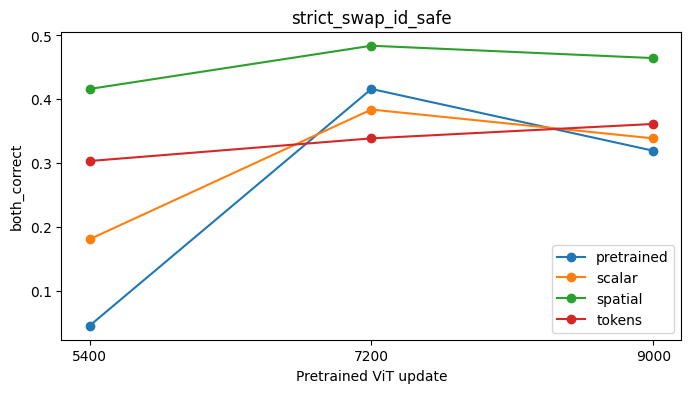

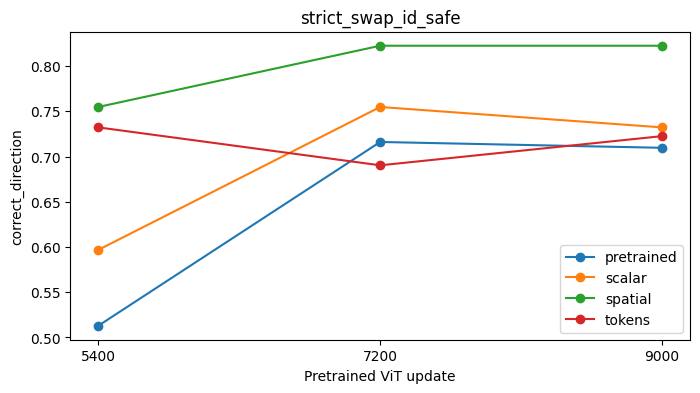

In [5]:
for metric, column, source in (("id_shape","accuracy",id_metrics),
                             ("id_conjunction_missing_shape","accuracy",id_metrics),
                             ("id_pair_count_controlled","balanced_accuracy",id_metrics),
                             ("strict_swap_id_safe","both_correct",edit_metrics),
                             ("strict_swap_id_safe","correct_direction",edit_metrics)):
    fig,ax=plt.subplots(figsize=(8,4))
    subset=source[(source.schedule=="prereq_mixed_pair_focus")&(source.metric==metric)]
    for name,frame in subset.groupby("readout"):
        mean=frame.groupby("step")[column].mean()
        ax.plot(mean.index,mean.values,marker="o",label=name)
    ax.set(xlabel="Pretrained ViT update",ylabel=column,title=metric,xticks=STEPS)
    ax.legend()
    plt.show()

## 5. Trained versus random visual pathways

Compare each new readout fitted on Mixed step-9,000 pretrained visual features against the same kind of readout fitted on random visual features **with the trained query embeddings retained**. If both perform similarly, a new decoder may simply recover low-level information rather than an abstraction acquired through pretrained ViT optimization.

In [6]:
random_ids=[]
random_edits=[]
for seed in SEEDS:
    folder=OUT_DIR/"random_visual"/f"random_visual_seed{seed}"
    for name,destination in (("id_metrics",random_ids),("edit_metrics",random_edits)):
        df=pd.read_csv(folder/(name+".csv"));df["seed"]=seed;destination.append(df)
random_id=pd.concat(random_ids,ignore_index=True)
random_edit=pd.concat(random_edits,ignore_index=True)
trained_id=id_metrics[(id_metrics.schedule=="mixed")&(id_metrics.step==9000)]
trained_edit=edit_metrics[(edit_metrics.schedule=="mixed")&(edit_metrics.step==9000)]
random_rows=[]
for metric,column,source in OUTCOMES:
    trained, random=(trained_id, random_id) if source=="id" else (trained_edit, random_edit)
    for name in ("scalar","spatial","tokens"):
        a=trained[(trained.metric==metric) & (trained.readout==name)].set_index("seed")[column]
        b=random[(random.metric==metric) & (random.readout==name)].set_index("seed")[column]
        difference=(a.loc[list(SEEDS)]-b.loc[list(SEEDS)])*100
        random_rows.append(dict(readout=name, metric=metric, outcome=column, contrast="trained_visual - random_visual",**paired_interval(difference)))
random_comparison=pd.DataFrame(random_rows)
display(random_comparison.round(2))

,readout,metric,outcome,contrast,n_seeds,mean_pp,sd_pp,ci95_low,ci95_high,positive_seeds
0,scalar,id_shape,accuracy,trained_visual - random_visual,5,15.86,2.20,13.12,18.59,5
1,spatial,id_shape,accuracy,trained_visual - random_visual,5,9.69,5.12,3.33,16.04,5
2,tokens,id_shape,accuracy,trained_visual - random_visual,5,2.11,2.00,-0.38,4.60,4
3,scalar,id_conjunction_missing_shape,accuracy,trained_visual - random_visual,5,-25.00,24.74,-55.72,5.72,1
4,spatial,id_conjunction_missing_shape,accuracy,trained_visual - random_visual,5,-8.85,14.56,-26.92,9.23,2
5,tokens,id_conjunction_missing_shape,accuracy,trained_visual - random_visual,5,-4.62,7.40,-13.80,4.57,2
6,scalar,id_pair_count_controlled,balanced_accuracy,trained_visual - random_visual,5,17.31,5.52,10.46,24.16,5
7,spatial,id_pair_count_controlled,balanced_accuracy,trained_visual - random_visual,5,18.45,7.60,9.01,27.89,5
8,tokens,id_pair_count_controlled,balanced_accuracy,trained_visual - random_visual,5,-1.58,7.58,-10.99,7.83,2
9,scalar,strict_swap_id_safe,both_correct,trained_visual - random_visual,5,26.13,8.33,15.78,36.48,5


## 6. Count-controlled Binding: threshold-free discrimination

The original 109-question strict Binding-swap source set contains exactly one queried-Color object and one queried-Shape object per scene. Join its source question IDs to the original ID predictions; calculate ROC-AUC using **probabilities rather than hard decisions**. The subset is not a perfectly matched causal benchmark. Treat the **five seeds** as the statistical units, not 109 independent replications.

In [7]:
from sklearn.metrics import roc_auc_score

auc_records=[]
leak_records=[]
joint_records=[]
selectivity_records=[]
operator_records=[]
for schedule in SCHEDULES:
    for seed in SEEDS:
        for step in STEPS:
            folder=DATA_DIR/f"{schedule}_seed{seed}_step{step}"
            id_pred=pd.read_csv(folder/"id_predictions.csv")
            edit_pred=pd.read_csv(folder/"edit_predictions.csv")
            keys=dict(schedule=schedule,seed=seed,step=step)

            strict=edit_pred[(edit_pred.group=="strict_swap")&(edit_pred.task=="pair")&(edit_pred.state=="before")]
            strict_ids=strict.pair_id.str.removeprefix("strict|")
            controlled=id_pred.set_index("example_id").loc[strict_ids]
            for name in READOUTS:
                auc_records.append(dict(**keys,readout=name,n=len(controlled),
                                        n_yes=int(controlled.label.sum()),
                                        n_no=int((controlled.label==0).sum()),
                                        auc=roc_auc_score(controlled.label,controlled["p_"+name])))

            # Grid swaps: 239 ID-safe edits, with four logically related questions per edit and state.
            grid=edit_pred[(edit_pred.group=="grid")&(edit_pred.edit=="binding_swap")&
                           (edit_pred.heldout_created==0)].copy()
            grid["edit_id"]=grid.pair_id.str.rsplit("|",n=1).str[0]
            labels=grid.pivot(index="edit_id",columns=["task","state"],values="label")
            direction=labels[("pair","after")]-labels[("pair","before")]
            for name in READOUTS:
                p=grid.pivot(index="edit_id",columns=["task","state"],values="p_"+name)
                prediction=(p>=.5).astype(int)
                correct=(prediction==labels)
                both={task:correct[(task,"before")]&correct[(task,"after")]
                      for task in ("pair","conjunction","shape","color")}
                invariant={task:prediction[(task,"before")]==prediction[(task,"after")]
                           for task in ("conjunction","shape","color")}
                for task in ("pair","conjunction","shape","color"):
                    delta=p[(task,"after")]-p[(task,"before")]
                    leak_records.append(dict(**keys,task=task,readout=name,n=len(p),
                        mean_abs_dp=delta.abs().mean(),mean_binding_aligned_dp=(delta*direction).mean(),
                        frac_binding_aligned=(delta*direction>0).mean(),
                        frac_flip=(prediction[(task,"before")]!=prediction[(task,"after")]).mean()))
                joint_records.append(dict(**keys,readout=name,n=len(p),
                    joint_pair_correct=both["pair"].mean(),joint_conj_correct=both["conjunction"].mean(),
                    joint_pair_conj_correct=(both["pair"]&both["conjunction"]).mean(),
                    joint_pair_conj_shape_correct=(both["pair"]&both["conjunction"]&both["shape"]).mean(),
                    joint_all_correct=(both["pair"]&both["conjunction"]&both["shape"]&both["color"]).mean(),
                    pair_correct_conj_invariant=(both["pair"]&invariant["conjunction"]).mean(),
                    pair_correct_all_invariant=(both["pair"]&invariant["conjunction"]&
                                                invariant["shape"]&invariant["color"]).mean()))
                dp_binding=(p[("pair","after")]-p[("pair","before")])*direction
                dp_conjunction=(p[("conjunction","after")]-p[("conjunction","before")])*direction
                selectivity_records.append(dict(**keys,readout=name,n=len(p),
                    binding_delta=dp_binding.mean(),conjunction_delta=dp_conjunction.mean(),
                    binding_minus_conjunction_delta=(dp_binding-dp_conjunction).mean(),
                    conjunction_flip_rate=(~invariant["conjunction"]).mean(),
                    joint_all_correct=(both["pair"]&both["conjunction"]&both["shape"]&both["color"]).mean()))

            # Intervention response matrix: all ID-safe oracle-validated grid interventions.
            edits=edit_pred[(edit_pred.group=="grid")&(edit_pred.heldout_created==0)].copy()
            for name in READOUTS:
                for (edit,task),part in edits.groupby(["edit","task"],sort=True):
                    pair=part.pivot(index="pair_id",columns="state",values=["label","p_"+name])
                    label_before=pair[("label","before")];label_after=pair[("label","after")]
                    before=pair[("p_"+name,"before")];after=pair[("p_"+name,"after")]
                    delta=after-before
                    changed=label_before!=label_after
                    flipped=(before>=.5)!=(after>=.5)
                    correct_both=((before>=.5)==label_before)&((after>=.5)==label_after)
                    operator_records.append(dict(**keys,readout=name,edit=edit,task=task,n=len(pair),
                        expected_label_change=float(changed.mean()),
                        mean_signed_delta=(delta*(label_after-label_before)).mean(),
                        mean_abs_delta=delta.abs().mean(),prediction_flip_rate=flipped.mean(),
                        both_correct=correct_both.mean()))

auc_df=pd.DataFrame(auc_records)
leak_df=pd.DataFrame(leak_records)
joint_df=pd.DataFrame(joint_records)
selectivity_df=pd.DataFrame(selectivity_records)
operator_df=pd.DataFrame(operator_records)
print("Count-controlled AUC records:",len(auc_df),"| grid-swap records:",len(leak_df),
      "| joint records:",len(joint_df),"| response-matrix records:",len(operator_df))
print("Strict subset:",auc_df.n.unique(),"| ID-safe grid swaps:",joint_df.n.unique())
display(auc_df[auc_df.step==9000].pivot_table(index="schedule",columns="readout",values="auc").round(3))

Count-controlled AUC records: 120 | grid-swap records: 480 | joint records: 120 | response-matrix records: 1200
Strict subset: [109] | ID-safe grid swaps: [239]


readout,pretrained,scalar,spatial,tokens
schedule,,,,
mixed,0.678,0.724,0.79,0.692
prereq_mixed_pair_focus,0.683,0.714,0.78,0.711


## 7. Operator leakage: does a Binding edit affect an independent Conjunction answer?

A Binding Color swap changes which attributes share an object while keeping Color and Shape presence invariant. For **the same ID-safe grid edits**, compare the probability change in Binding and the unintended change in Conjunction, Color and Shape. A Conjunction hard-prediction flip is a functional invariance failure, not by itself proof of an internal causal path. The signed change is aligned with the Binding oracle's answer change. Report seed means separately for both curricula.

In [8]:
final_leak=leak_df[leak_df.step==9000]
for schedule in SCHEDULES:
    print("\n",schedule,"— operator response on ID-safe Binding swaps")
    display(final_leak[final_leak.schedule==schedule].pivot_table(
        index="task",columns="readout",values=["mean_binding_aligned_dp","frac_flip"]).round(3))

final_selectivity=selectivity_df[selectivity_df.step==9000]
display(final_selectivity.pivot_table(index="schedule",columns="readout",
        values=["binding_delta","conjunction_delta","binding_minus_conjunction_delta",
                "conjunction_flip_rate"]).round(3))


 mixed — operator response on ID-safe Binding swaps


frac_flip                       mean_binding_aligned_dp         \
readout     pretrained scalar spatial tokens              pretrained scalar   
task                                                                          
color            0.011  0.011   0.018  0.065                   0.002 -0.001   
conjunction      0.134  0.148   0.279  0.300                   0.046  0.055   
pair             0.313  0.343   0.481  0.408                   0.096  0.125   
shape            0.164  0.173   0.177  0.195                   0.003  0.002   

                            
readout     spatial tokens  
task                        
color        -0.000  0.007  
conjunction   0.152  0.078  
pair          0.270  0.138  
shape         0.005  0.012


 prereq_mixed_pair_focus — operator response on ID-safe Binding swaps


frac_flip                       mean_binding_aligned_dp         \
readout     pretrained scalar spatial tokens              pretrained scalar   
task                                                                          
color            0.019  0.013   0.022  0.065                   0.002  0.002   
conjunction      0.138  0.161   0.309  0.280                   0.061  0.068   
pair             0.345  0.408   0.500  0.415                   0.123  0.148   
shape            0.162  0.169   0.178  0.216                  -0.003 -0.003   

                            
readout     spatial tokens  
task                        
color         0.002  0.003  
conjunction   0.165  0.075  
pair          0.272  0.153  
shape        -0.000  0.014

binding_delta                        \
readout                    pretrained scalar spatial tokens   
schedule                                                      
mixed                           0.096  0.125   0.270  0.138   
prereq_mixed_pair_focus         0.123  0.148   0.272  0.153   

                        binding_minus_conjunction_delta                        \
readout                                      pretrained scalar spatial tokens   
schedule                                                                        
mixed                                             0.050   0.07   0.118  0.060   
prereq_mixed_pair_focus                           0.062   0.08   0.107  0.078   

                        conjunction_delta                        \
readout                        pretrained scalar spatial tokens   
schedule                                                          
mixed                               0.046  0.055   0.152  0.078   
prereq_mixed_pair_focus             0.061  0.068   0.165  0.075   

                        conjunction_flip_rate                        
readout                            pretrained scalar spatial tokens  
schedule                                                             
mixed                                   0.134  0.148   0.279   0.30  
prereq_mixed_pair_focus                 0.138  0.161   0.309   0.28

## 8. Joint correctness: can the model answer four related questions consistently?

Evaluate all **eight task–state answers** from the same ID-safe 239-swap grid: Color, Shape, Conjunction and Binding, before and after the edit. `joint_all_correct` requires every answer to match its oracle. `pair_correct_conj_invariant` is a weaker criterion: Binding must be correct at both endpoints, but Conjunction only needs to *retain the same hard prediction*. The former is more demanding and cannot be replaced by the latter.

In [9]:
display(joint_df[joint_df.step==9000].pivot_table(index="schedule",columns="readout",
    values=["joint_pair_correct","joint_pair_conj_correct","joint_all_correct",
            "pair_correct_conj_invariant"]).round(3))

new_outcomes=(('auc_df','auc'),('leak_conjunction_flip','frac_flip'),
              ('joint_all','joint_all_correct'),('binding_minus_conjunction','binding_minus_conjunction_delta'))
new_rows=[]
for schedule in SCHEDULES:
    for step in STEPS:
        for name,column in new_outcomes:
            if name=='auc_df': df=auc_df
            elif name=='leak_conjunction_flip': df=leak_df[leak_df.task=='conjunction']
            elif name=='joint_all': df=joint_df
            else: df=selectivity_df
            source=df[(df.schedule==schedule)&(df.step==step)]
            wide=source.pivot(index="seed",columns="readout",values=column).loc[list(SEEDS)]
            for newer,older in CONTRASTS:
                differences=(wide[newer]-wide[older])*100
                new_rows.append(dict(schedule=schedule,step=step,metric=name,
                                     contrast=newer+" - "+older,
                                     **paired_interval(differences)))
new_paired=pd.DataFrame(new_rows)
print("Paired effects at step 9000, in percentage points (AUC ×100):")
display(new_paired[(new_paired.step==9000)&(new_paired.contrast=='spatial - scalar')].round(2))

joint_all_correct                        \
readout                        pretrained scalar spatial tokens   
schedule                                                          
mixed                               0.115  0.146   0.179  0.119   
prereq_mixed_pair_focus             0.137  0.167   0.165  0.115   

                        joint_pair_conj_correct                        \
readout                              pretrained scalar spatial tokens   
schedule                                                                
mixed                                     0.164  0.188   0.247  0.172   
prereq_mixed_pair_focus                   0.194  0.236   0.242  0.183   

                        joint_pair_correct                        \
readout                         pretrained scalar spatial tokens   
schedule                                                           
mixed                                0.244  0.269   0.426  0.319   
prereq_mixed_pair_focus              0.284  0.336   0.449  0.331   

                        pair_correct_conj_invariant                        
readout                                  pretrained scalar spatial tokens  
schedule                                                                   
mixed                                         0.172  0.198   0.261  0.185  
prereq_mixed_pair_focus                       0.202  0.249   0.256  0.196

Paired effects at step 9000, in percentage points (AUC ×100):


,schedule,step,metric,contrast,n_seeds,mean_pp,sd_pp,ci95_low,ci95_high,positive_seeds
24,mixed,9000,auc_df,spatial - scalar,5,6.64,6.85,-1.86,15.15,4
27,mixed,9000,leak_conjunction_flip,spatial - scalar,5,13.05,5.76,5.91,20.20,5
30,mixed,9000,joint_all,spatial - scalar,5,3.35,4.24,-1.91,8.61,4
33,mixed,9000,binding_minus_conjunction,spatial - scalar,5,4.79,3.94,-0.10,9.68,5
60,prereq_mixed_pair_focus,9000,auc_df,spatial - scalar,5,6.61,4.51,1.01,12.22,5
63,prereq_mixed_pair_focus,9000,leak_conjunction_flip,spatial - scalar,5,14.81,9.01,3.63,25.99,5
66,prereq_mixed_pair_focus,9000,joint_all,spatial - scalar,5,-0.17,5.31,-6.77,6.43,2
69,prereq_mixed_pair_focus,9000,binding_minus_conjunction,spatial - scalar,5,2.74,2.76,-0.69,6.18,5


## 9. New diagnostic: counterfactual operator-response matrix

This is a behavioral intervention analysis, not Network Dissection or a causal localization of internal units. For each **ID-safe, oracle-validated edit**, compare how each task's Yes probability changes. Changing a Shape should affect Shape and Conjunction but not Color; changing Color should affect Color and Conjunction but not Shape; swapping a Binding should affect Binding but leave independent attribute presence and Conjunction intact. This yields an *operator response signature* that is more informative than single-task accuracy.

`expected_label_change` is calculated from the oracle, not inferred from the model's prediction. For tasks whose oracle answer is invariant, interpret **prediction_flip_rate** and **mean_abs_delta**; for tasks whose oracle answer changes, interpret **both_correct** and **mean_signed_delta**. A high probability response is not sufficient unless the predictions are correct at both endpoints.


 mixed — spatial readout, ID-safe edits, final pretrained checkpoint


n  expected_label_change  both_correct  \
edit         task                                                      
binding_swap color        239.0                    0.0         0.982   
             conjunction  239.0                    0.0         0.664   
             pair         239.0                    1.0         0.426   
             shape        239.0                    0.0         0.627   
color_insert color        545.0                    1.0         0.977   
             conjunction  545.0                    1.0         0.866   
             shape        545.0                    0.0         0.525   
shape_insert color        258.0                    0.0         0.986   
             conjunction  258.0                    1.0         0.267   
             shape        258.0                    1.0         0.219   

                          prediction_flip_rate  mean_abs_delta  
edit         task                                               
binding_swap color                       0.018           0.035  
             conjunction                 0.279           0.226  
             pair                        0.481           0.324  
             shape                       0.177           0.120  
color_insert color                       0.977           0.956  
             conjunction                 0.866           0.744  
             shape                       0.198           0.121  
shape_insert color                       0.013           0.029  
             conjunction                 0.312           0.230  
             shape                       0.244           0.135

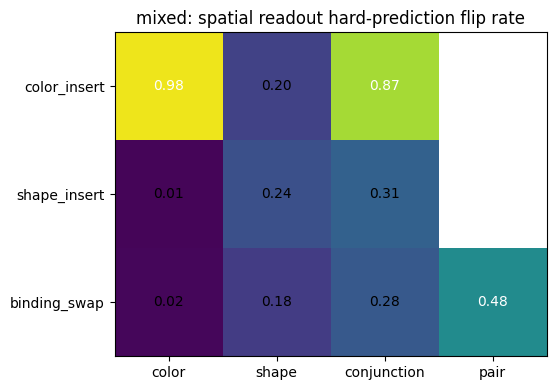


 prereq_mixed_pair_focus — spatial readout, ID-safe edits, final pretrained checkpoint


n  expected_label_change  both_correct  \
edit         task                                                      
binding_swap color        239.0                    0.0         0.978   
             conjunction  239.0                    0.0         0.646   
             pair         239.0                    1.0         0.449   
             shape        239.0                    0.0         0.619   
color_insert color        545.0                    1.0         0.979   
             conjunction  545.0                    1.0         0.872   
             shape        545.0                    0.0         0.531   
shape_insert color        258.0                    0.0         0.983   
             conjunction  258.0                    1.0         0.280   
             shape        258.0                    1.0         0.182   

                          prediction_flip_rate  mean_abs_delta  
edit         task                                               
binding_swap color                       0.022           0.039  
             conjunction                 0.309           0.238  
             pair                        0.500           0.327  
             shape                       0.178           0.123  
color_insert color                       0.979           0.955  
             conjunction                 0.872           0.741  
             shape                       0.209           0.127  
shape_insert color                       0.016           0.034  
             conjunction                 0.312           0.222  
             shape                       0.218           0.129

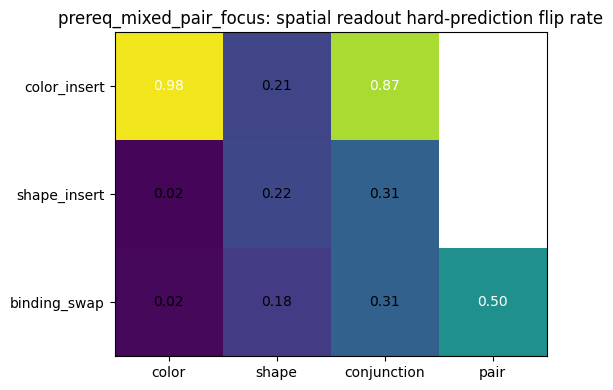

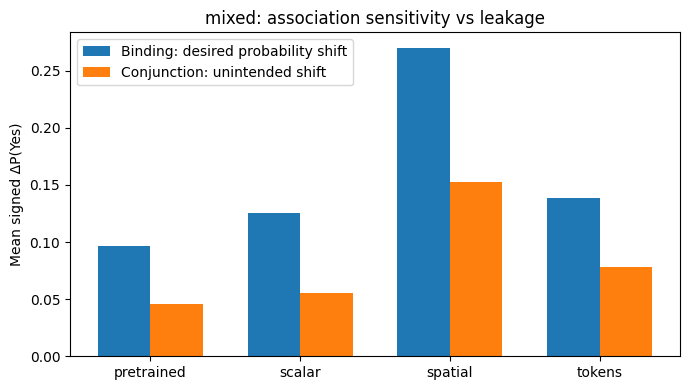

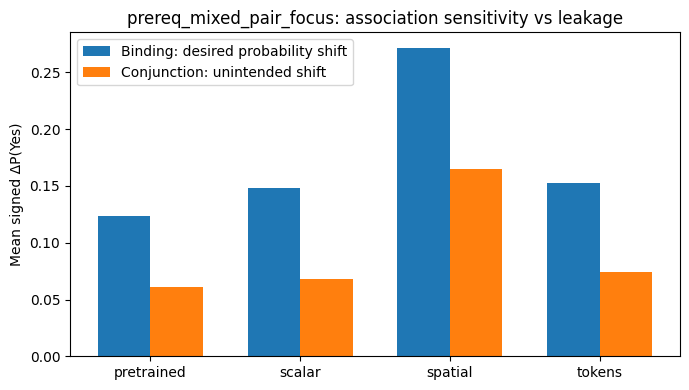

In [10]:
operator_final=operator_df[operator_df.step==9000]
for schedule in SCHEDULES:
    print("\n",schedule,"— spatial readout, ID-safe edits, final pretrained checkpoint")
    frame=operator_final[(operator_final.schedule==schedule)&(operator_final.readout=='spatial')]
    display(frame.groupby(["edit","task"])[["n","expected_label_change","both_correct",
                                               "prediction_flip_rate","mean_abs_delta"]].mean().round(3))
    fig,ax=plt.subplots(figsize=(8,4))
    m=frame.pivot_table(index="edit",columns="task",values="prediction_flip_rate").reindex(
        index=["color_insert","shape_insert","binding_swap"],
        columns=["color","shape","conjunction","pair"])
    ax.imshow(m.to_numpy(),vmin=0,vmax=1)
    for i in range(len(m.index)):
        for j in range(len(m.columns)):
            if np.isfinite(m.iloc[i,j]):ax.text(j,i,f"{m.iloc[i,j]:.2f}",ha="center",va="center",color="white" if m.iloc[i,j]>.45 else "black")
    ax.set_xticks(range(len(m.columns)),m.columns)
    ax.set_yticks(range(len(m.index)),m.index)
    ax.set_title(schedule+": spatial readout hard-prediction flip rate")
    fig.tight_layout()
    fig.savefig(ANALYSIS_DIR/f"operator_flip_matrix_{schedule}.png",dpi=160)
    plt.show()

for schedule in SCHEDULES:
    fig,ax=plt.subplots(figsize=(7,4))
    subset=selectivity_df[(selectivity_df.schedule==schedule)&(selectivity_df.step==9000)]
    mean=subset.groupby('readout')[["binding_delta","conjunction_delta"]].mean().reindex(READOUTS)
    xs=np.arange(len(mean));width=.35
    ax.bar(xs-width/2,mean.binding_delta,width,label="Binding: desired probability shift")
    ax.bar(xs+width/2,mean.conjunction_delta,width,label="Conjunction: unintended shift")
    ax.set_xticks(xs,mean.index)
    ax.set(ylabel="Mean signed ΔP(Yes)",title=schedule+": association sensitivity vs leakage")
    ax.legend();fig.tight_layout()
    fig.savefig(ANALYSIS_DIR/f"binding_conjunction_tradeoff_{schedule}.png",dpi=160)
    plt.show()

## 10. Persist derived results

Every derived CSV and figure below is recreated from the original per-run `id_predictions.csv` / `edit_predictions.csv`. These are analysis products; **no retraining and no new original model observations** are implied. Raw data remains the authoritative source.

In [11]:
for name,frame in (("count_controlled_binding_auc",auc_df),
                   ("binding_swap_operator_leakage",leak_df),
                   ("binding_swap_joint_consistency",joint_df),
                   ("binding_conjunction_selectivity",selectivity_df),
                   ("counterfactual_operator_response",operator_df),
                   ("additional_paired_contrasts",new_paired)):
    frame.to_csv(ANALYSIS_DIR/(name+".csv"),index=False)
print("Derived tables and diagnostic figures saved to",ANALYSIS_DIR)

Derived tables and diagnostic figures saved to c:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\medium_world\experiments\architecture_localization\analysis


### Interpretability methods worth investigating next

The operator-response matrix tests functional dependence **from predictions already saved**. It does not identify which internal patches or concepts caused a response. To localize that mechanism, a separate intervention study could replace activations for selected image patches or score-map regions between matched before/after scenes (**activation patching**). That requires rerunning inference with the original checkpoints and fitted readouts, but no retraining. It can distinguish association evidence in the visual tokens from interactions introduced by the score-map and final readout.

Other options: **linear CKA** compares representation geometry across the three pretrained training stages, while **TCAV** tests sensitivity to a supervised Shape concept direction. Neither proves causal reuse of a particular concept by the deployed decision pathway. Priority: activation patching at token/score-map boundaries, with unmodified-source controls and no claims of object slots. Relevant primary references: [Kornblith et al. (2019), CKA](https://proceedings.mlr.press/v97/kornblith19a.html), [Kim et al. (2018), TCAV](https://proceedings.mlr.press/v80/kim18d.html), [Izadi et al. (2026), ViT activation patching](https://arxiv.org/abs/2603.13652).

## 11. Save original summaries

Saved output tables preserve the observed comparisons without writing interpretations in advance. Review per-seed results and confusion/response biases before attributing an advantage to spatial aggregation.

In [12]:
for name, frame in (("id_metrics_all",id_metrics),("edit_metrics_all",edit_metrics),
                   ("paired_readout_contrasts",paired),("random_visual_contrasts",random_comparison)):
    frame.to_csv(ANALYSIS_DIR/(name+".csv"),index=False)
print("Analysis tables saved:", ANALYSIS_DIR)

Analysis tables saved: c:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\medium_world\experiments\architecture_localization\analysis


## Interpretation questions (answer after running)

1. Does Spatial improve missing-Shape Conjunction negatives **without** losing Shape-present accuracy or Color performance?
2. Does Spatial improve count-controlled Binding and strict swap both-correct / correct-direction scores, including the **no-held-out-created** swap subset?
3. Does Token improve further over Spatial? A gain would implicate lost or poorly formed attribute-score evidence, but not isolate its source.
4. Do the Shape recoloring **present and absent** controls both stay correct? Check probability changes, not only hard prediction invariance.
5. Are changes consistent across seeds and visible under the random-visual controls? The OOD-dev generator has known shortcuts; these ID-based diagnostics cannot establish systematic novel-combination generalization.

Additional questions: Does a readout improve Binding while increasing incorrect Conjunction flips? Does the joint all-task score change in the same direction? Which oracle-validated edits affect unrelated task outputs? Are any contrasts robust across five paired seeds (unadjusted exploratory intervals)?